In [1]:
import sys
import os
sys.path.append(os.path.abspath('../../../'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from functions.preproc import *
from functions.ensembles import *
from functions.repeated_cv import *
from functions.postproc import *

from sklearn import set_config
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import make_scorer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import StratifiedKFold
from sksurv.metrics import integrated_brier_score
from sksurv.metrics import concordance_index_ipcw
from sksurv.nonparametric import kaplan_meier_estimator
from sklearn.inspection import permutation_importance

from sksurv.ensemble import RandomSurvivalForest
from sksurv.metrics import concordance_index_censored
from sksurv.util import Surv
from sksurv.ensemble import GradientBoostingSurvivalAnalysis
from sksurv.ensemble import ComponentwiseGradientBoostingSurvivalAnalysis

import time
set_config(display="text")  # displays text representation of estimators

In [2]:
dataset = pd.read_csv("../../data/data.csv")

diagnosis_variables = []

with open("../../data/diagnosis.txt", "r") as file:
    for line in file:
        diagnosis_variables.append(line.strip())

treatment_variables = []
with open("../../data/treatment.txt", "r") as file:
    for line in file:
        treatment_variables.append(line.strip())

survival_dataset = dataset.drop('Unnamed: 0', axis=1)

feature_columns = treatment_variables + diagnosis_variables
# Guard: data.csv must be the current build produced by
# new_approaches/data/new_new_data.ipynb (the drop_first=False twin of the Cox
# build). The older April build has 41 features and neither of these markers,
# and training on it silently breaks comparability with cox_new_new.csv.
expected_markers = ['Neoadjuvant (Only) therapy with biological drugs',
                    'Diagnostic panel missingness pattern_missing_3']
missing_markers = [c for c in expected_markers if c not in survival_dataset.columns]
assert not missing_markers, (
    f'data.csv looks like the old build (missing {missing_markers}). '
    'Re-run new_approaches/data/new_new_data.ipynb to regenerate '
    'data.csv / diagnosis.txt / treatment.txt.')
assert len(survival_dataset) == 3228, (
    f'expected 3228 rows to match the cox build, got {len(survival_dataset)}')

In [3]:
# Cap survival days at 1825 and set event status to 0 for censored cases
survival_dataset.loc[survival_dataset['Survival days'] > 1826, 'Regional LN recurrence'] = 0
survival_dataset.loc[survival_dataset['Survival days'] > 1826, 'Survival days'] = 1826

# Prepare data
data_x = survival_dataset[feature_columns]
data_y = Surv.from_arrays(
    event=survival_dataset['Regional LN recurrence'],
    time=survival_dataset['Survival days']
)
groups = survival_dataset['PERSON_ID']

# Stratification settings (toggle this flag)
n_splits = 5
use_time_strata = False  # Set to False to use outcome-only stratification
max_time_bins = 3

event_col = survival_dataset['Regional LN recurrence'].astype(int)
time_col = survival_dataset['Survival days']

strata_labels = None
chosen_bins = None
recurrence_mask = (event_col == 1)

if use_time_strata:
    # Outcome-Length stratification: time bins only for recurrence cases
    for n_bins in range(max_time_bins, 1, -1):
        try:
            # Build quantile bins using only recurrence cases
            recurrence_time_bins = pd.qcut(
                time_col.loc[recurrence_mask], q=n_bins, labels=False, duplicates='drop'
            )

            # Non-recurrence rows share one label; recurrence rows get time-bin labels
            candidate_labels = pd.Series('0_noevent', index=survival_dataset.index, dtype='object')
            candidate_labels.loc[recurrence_mask] = (
                '1_' + recurrence_time_bins.astype(int).astype(str)
            ).values

            # Every stratum must have at least n_splits samples for stable balancing
            if candidate_labels.value_counts().min() >= n_splits:
                strata_labels = candidate_labels
                chosen_bins = int(recurrence_time_bins.nunique())
                break
        except ValueError:
            continue

if strata_labels is None:
    # Explicit switch OR sparse recurrence-time bins -> outcome-only stratification
    strata_labels = event_col.astype(str)
    if use_time_strata:
        print('Fallback: using outcome-only stratification (recurrence time bins too sparse).')
    else:
        print('Using outcome-only stratification (time-based stratification disabled).')
else:
    print(f'Using recurrence-only time stratification with {chosen_bins} time bins.')

# sgkf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=12)
# cv = sgkf.split(X=data_x, y=strata_labels)

# train_index, test_index = next(cv)

manual_splits, manual_fold_summary = build_manual_stratified_group_folds(
    event_series=event_col,
    group_series=groups,
    strata_series=strata_labels,
    keep_groups_for_events=False,
    n_splits=n_splits,
    random_state=302
)

print('Manual grouped fold balancing summary:')
print(manual_fold_summary.to_string(index=False))

# Keep variable name for compatibility in later cells
cv = manual_splits
train_index, test_index = manual_splits[0]

x_train = data_x.iloc[train_index]
y_train = data_y[train_index]

x_test = data_x.iloc[test_index]
y_test = data_y[test_index]

subsampling = survival_dataset.iloc[train_index].copy()

print(f'Train size: {len(train_index)}, Test size: {len(test_index)}')

Using outcome-only stratification (time-based stratification disabled).
Manual grouped fold balancing summary:
 fold  target_events  assigned_events  target_samples  assigned_samples  valid_event_rate  target_event_strata_1  assigned_event_strata_1
    1              6                6             646               646          0.009288                      6                        6
    2              6                6             646               646          0.009288                      6                        6
    3              5                5             646               646          0.007740                      5                        5
    4              5                5             645               645          0.007752                      5                        5
    5              5                5             645               645          0.007752                      5                        5
Train size: 2582, Test size: 646


## Grid search

Set up to be directly comparable with `cox.ipynb` / `cox_new_new.csv`:

| | setting |
|---|---|
| data | `../../data/data.csv` (same cohort as the Cox run, one-hot without `drop_first`) |
| outer split | `build_manual_stratified_group_folds(..., n_splits=5, random_state=12)`, fold index 3 |
| inner CV | `generate_cv_splits(n_splits=4, n_repeats=5, base_random_state=42)` |
| selection metric | Harrell's C-index |

`generate_cv_splits` is shared by every grid-search function in
`functions/repeated_cv.py`, so with the same `n_splits` / `n_repeats` /
`base_random_state` the 20 train/validation folds are **identical** to the ones
the Cox run scored on — the C-indices compare fold for fold.

The training split carries only 22 events (~17 per inner training fold, ~5 per
validation fold). The grids below therefore search regularisation strength
rather than model capacity, and are kept deliberately small: every extra grid
point is another chance for the CV winner to be picked by noise.

In [4]:
# n_estimators is NOT in param_grid: gbm_staged_repeated_grid_search fits one
# model per fold at max(n_estimators_grid) and reads the validation C-index off
# staged_predict at every checkpoint. A boosting model with N rounds contains
# every shorter model as a prefix, so this is exact -- not an approximation --
# and it makes the whole n_estimators axis free (the staged walk costs ~0.04 s
# against ~40 s for the fit).
#
# Stage 1 (reduced): dropped learning_rate=0.01 to cut combinations 24 -> 16.
# lr=0.01 was the one axis that overlapped almost entirely with 0.05/0.1 given
# enough rounds, so it's the cheapest thing to drop for a combinations cut.
#
# n_estimators_grid is kept at 1000 (not narrowed further): the user's prior
# experience with this GBM model is that the larger n_estimators values gave
# the good results (the calibration cell below still has n_estimators=4000
# hardcoded from that experience) -- a single trial fold looking flat past
# round 200 isn't strong enough evidence to cut that region out of the search.
param_grid = {
    # Shrinkage. Low rates need many rounds; the checkpoints below span enough
    # range to let each rate find its own optimum.
    'learning_rate': [0.05, 0.1],
    # Interaction depth. With ~17 events per inner training fold, depth 1
    # (additive stumps) and depth 2 (a single interaction) are the defensible
    # choices; depth 3+ fits 8-leaf trees to a handful of events.
    'max_depth': [1, 2],
    'min_samples_leaf': [5, 15],
    # Stochastic boosting: the main regulariser available here.
    'subsample': [0.7, 1.0],
    'max_features': [None],
}

# Same n_estimators_grid as before the reduction -- see note above on why this
# axis wasn't narrowed. If the 1000-round checkpoint is still the best for any
# combo, that's the signal to extend a follow-up stage out toward 4000 rather
# than assume 1000 was enough.
n_estimators_grid = [10, 25, 50, 75, 100, 150, 200, 300, 400, 600, 800, 1000]

metrics = ['c-index']

n_combinations = 1
for values in param_grid.values():
    n_combinations *= len(values)
print(f'{n_combinations} combinations x 20 folds = {n_combinations * 20} model fits '
      f'at n_estimators={max(n_estimators_grid)}')
print(f'-> {n_combinations * len(n_estimators_grid)} effective grid points, '
      f'{n_combinations * len(n_estimators_grid) * 20} evaluations')

# Wider alternative: max_features is a regulariser here, and costs nothing extra
# (GBM fit time is dominated by the Cox gradient, not the split search):
#     'max_features': ['sqrt', None]

16 combinations x 20 folds = 320 model fits at n_estimators=1000
-> 192 effective grid points, 3840 evaluations


In [5]:
# Same 4x5 folds as the Cox run. The previous version of this cell put
# n_estimators=4000 in the grid, which costs ~5.6 min per fit (~2 h per grid
# point at 20 folds) and sits far past the point where this model stops
# improving; the staged search gets checkpoints out of one fit for free.
#
# 16 combinations x 20 fits at 1000 rounds, ~40 s each (dropping
# learning_rate=0.01 -- see param_grid cell -- cuts combinations 24 -> 16
# without touching n_estimators_grid, since the good region historically
# lived at large n_estimators, not the low end). Expect roughly 3-3.5 h.
results_df, summary_df, best_params = gbm_staged_repeated_grid_search(
    X=x_train, y=y_train,
    param_grid=param_grid,
    metrics=metrics,
    n_estimators_grid=n_estimators_grid,
    model_class=GradientBoostingSurvivalAnalysis,   # loss='coxph' by default
    model_name='GBM Model',
    scale_data=False,               # trees are scale invariant
    continuous_features=None,
    random_state=42,
    n_splits=4, n_repeats=5, base_random_state=42,
    verbose=True
)


GBM MODEL STAGED REPEATED GRID SEARCH
Model: GradientBoostingSurvivalAnalysis
Scaling: No
Metrics: ['c-index']
Parameter Grid (excluding n_estimators):
  - learning_rate: [0.05, 0.1]
  - max_depth: [1, 2]
  - min_samples_leaf: [5, 15]
  - subsample: [0.7, 1.0]
  - max_features: [None]
  - n_estimators (staged): [10, 25, 50, 75, 100, 150, 200, 300, 400, 600, 800, 1000]
Base combinations (model fits per fold): 16
Effective grid points: 192
Folds per repetition: 4
Repetitions: 5
Model fits: 320 (at n_estimators=1000)
Evaluations: 3840

[1/16] Testing params: {'learning_rate': 0.05, 'max_depth': 1, 'min_samples_leaf': 5, 'subsample': 0.7, 'max_features': None}
  c-index: best 0.8538 ± 0.0606 @ n_estimators=600
[2/16] Testing params: {'learning_rate': 0.05, 'max_depth': 1, 'min_samples_leaf': 5, 'subsample': 1.0, 'max_features': None}
  Elapsed: 11.2min, Est. remaining: 167.5min
  c-index: best 0.8309 ± 0.0687 @ n_estimators=800
[3/16] Testing params: {'learning_rate': 0.05, 'max_depth': 1

KeyboardInterrupt: 

In [ ]:
# Drop configurations where any fold failed, then match cox_new_new.csv's
# layout: a CV column (coefficient of variation = std / mean, i.e. fold-to-fold
# instability per unit of performance) and best-first ordering.
gbm_clean = clean_cox_data(summary_df)

# groupby turns None hyperparameters into NaN, which is indistinguishable from a
# genuinely missing value once written to CSV. Spell them out instead:
# max_depth=None means unlimited depth, max_features=None means all features.
param_cols = [c for c in gbm_clean.columns
              if not c.startswith(tuple(metrics)) and c != 'CV']
for col in param_cols:
    if gbm_clean[col].isna().any():
        gbm_clean[col] = gbm_clean[col].astype(object).where(gbm_clean[col].notna(), 'None')

gbm_clean['CV'] = gbm_clean['c-index_std'] / gbm_clean['c-index_mean']
gbm_clean = gbm_clean.sort_values('c-index_mean', ascending=False).reset_index(drop=True)
gbm_clean.to_csv('gbm_new.csv', index=False)

display_cols = [c for c in gbm_clean.columns if '_repeat_' not in c]
print(gbm_clean[display_cols].head(15).to_string(index=False))

## Grid search — stage 2

Stage 1 (`learning_rate` narrowed to `[0.05, 0.1]`, everything else at the
original range) was interrupted after combo 6/16, all six at
`learning_rate=0.05`. From what finished:

| finding | evidence |
|---|---|
| `subsample=0.7` beats `1.0` | every matched pair so far: 0.8538 vs 0.8309, 0.8539 vs 0.8318, 0.8403 vs 0.8346 — a consistent ~0.02-0.023 C-index gap, and `subsample=0.7` fits faster too (each round only sees 70% of rows) |
| best `n_estimators` sits at the top of the grid in half the finished combos | 600, 800, 1000, 1000, 600, 1000 — consistent with the calibration cell's `n_estimators=4000` and the user's recollection that this model wants large `n_estimators` |
| `min_samples_leaf` 5 vs 15 | nearly tied at `depth=1, subsample=0.7` (0.8538 vs 0.8539) — no signal yet |
| `max_depth` 1 vs 2 | one comparison only (`leaf=5, subsample=0.7`): depth=1 ahead, 0.8538 vs 0.8403 |
| `learning_rate=0.1` | untested — stage 1 stopped before reaching it |

Stage 2 acts on the one signal that's both strong and consistent
(`subsample=0.7`) to free up budget, and spends it on the two things stage 1
hadn't reached yet: `learning_rate=0.1`, and enough `n_estimators` headroom
to find where the C-index actually stops climbing (extended to 2000, not
straight to 4000 — stay staged and confirm the next step up before jumping
to the historical value, same reasoning as the RSF search). `max_depth` and
`min_samples_leaf` stay as an open 2x2 since neither has enough evidence yet
to drop a value.

In [9]:
# Stage 2, back to the staged/free mechanism (gbm_staged_repeated_grid_search):
# one fit per fold at max(n_estimators_grid), every smaller checkpoint read
# off that same fit for free -- roughly 1.8x cheaper than treating
# n_estimators as a normal param_grid axis for the same set of values, since
# nothing is refit per checkpoint.
param_grid_stage2 = {
    'learning_rate': [0.05, 0.1],
    'max_depth': [1, 2],
    'min_samples_leaf': [5, 15],
    'subsample': [0.7, 1.0],
    'max_features': [None],
}

n_estimators_grid_stage2 = [2000, 2500]

metrics = ['c-index']

n_combinations = 1
for values in param_grid_stage2.values():
    n_combinations *= len(values)
print(f'{n_combinations} combinations x 20 folds = {n_combinations * 20} model fits '
      f'at n_estimators={max(n_estimators_grid_stage2)}')
print(f'-> {n_combinations * len(n_estimators_grid_stage2)} effective grid points, '
      f'{n_combinations * len(n_estimators_grid_stage2) * 20} evaluations')

16 combinations x 20 folds = 320 model fits at n_estimators=2500
-> 32 effective grid points, 640 evaluations


In [10]:
# Same 4x5 folds as stage 1 / the Cox run. 16 combinations x 20 folds at
# n_estimators=2000, checkpoints at 600/1000/2000 read for free off each fit.
# The one subsample=0.7 combo that ran earlier took ~28-30min for its 20
# folds at this max, so expect roughly 7-8h for all 16 (subsample=1.0 combos
# ran slower in stage 1, so not evenly split). Safe to stop early:
# gbm_staged_repeated_grid_search returns whatever combos finished instead
# of losing them to a KeyboardInterrupt.
results_df_stage2, summary_df_stage2, best_params_stage2 = gbm_staged_repeated_grid_search(
    X=x_train, y=y_train,
    param_grid=param_grid_stage2,
    metrics=metrics,
    n_estimators_grid=n_estimators_grid_stage2,
    model_class=GradientBoostingSurvivalAnalysis,   # loss='coxph' by default
    model_name='GBM Model (stage 2)',
    scale_data=False,               # trees are scale invariant
    continuous_features=None,
    random_state=42,
    n_splits=4, n_repeats=5, base_random_state=42,
    verbose=True
)


GBM MODEL (STAGE 2) STAGED REPEATED GRID SEARCH
Model: GradientBoostingSurvivalAnalysis
Scaling: No
Metrics: ['c-index']
Parameter Grid (excluding n_estimators):
  - learning_rate: [0.05, 0.1]
  - max_depth: [1, 2]
  - min_samples_leaf: [5, 15]
  - subsample: [0.7, 1.0]
  - max_features: [None]
  - n_estimators (staged): [2000, 2500]
Base combinations (model fits per fold): 16
Effective grid points: 32
Folds per repetition: 4
Repetitions: 5
Model fits: 320 (at n_estimators=2500)
Evaluations: 640

[1/16] Testing params: {'learning_rate': 0.05, 'max_depth': 1, 'min_samples_leaf': 5, 'subsample': 0.7, 'max_features': None}
  c-index by n_estimators:
    n_estimators=2000  0.8716 ± 0.0502  <- best
    n_estimators=2500  0.8714 ± 0.0509
[2/16] Testing params: {'learning_rate': 0.05, 'max_depth': 1, 'min_samples_leaf': 5, 'subsample': 1.0, 'max_features': None}
  Elapsed: 27.5min, Est. remaining: 413.0min
  c-index by n_estimators:
    n_estimators=2000  0.8586 ± 0.0640
    n_estimators=250

In [11]:
# Drop configurations where any fold failed, then match cox_new_new.csv's
# layout: a CV column (coefficient of variation = std / mean, i.e. fold-to-fold
# instability per unit of performance) and best-first ordering.
gbm_stage2_clean = clean_cox_data(summary_df_stage2)

# groupby turns None hyperparameters into NaN, which is indistinguishable from a
# genuinely missing value once written to CSV. Spell them out instead:
# max_depth=None means unlimited depth, max_features=None means all features.
param_cols = [c for c in gbm_stage2_clean.columns
              if not c.startswith(tuple(metrics)) and c != 'CV']
for col in param_cols:
    if gbm_stage2_clean[col].isna().any():
        gbm_stage2_clean[col] = gbm_stage2_clean[col].astype(object).where(gbm_stage2_clean[col].notna(), 'None')

gbm_stage2_clean['CV'] = gbm_stage2_clean['c-index_std'] / gbm_stage2_clean['c-index_mean']
gbm_stage2_clean = gbm_stage2_clean.sort_values('c-index_mean', ascending=False).reset_index(drop=True)
gbm_stage2_clean.to_csv('gbm_stage2.csv', index=False)

display_cols = [c for c in gbm_stage2_clean.columns if '_repeat_' not in c]
print(gbm_stage2_clean[display_cols].head(15).to_string(index=False))

  Checked 20 c-index fold columns and 0 c-index-ipcw fold columns
  Removed 2 rows with missing fold values (28 -> 26)
 learning_rate  max_depth  min_samples_leaf  subsample max_features  n_estimators  c-index_mean  c-index_std       CV
          0.10          1                15        0.7         None          2500      0.876015     0.057448 0.065579
          0.10          1                15        1.0         None          2000      0.873895     0.050941 0.058292
          0.10          1                15        1.0         None          2500      0.873370     0.052842 0.060503
          0.05          1                15        0.7         None          2500      0.872919     0.055358 0.063417
          0.10          1                15        0.7         None          2000      0.872813     0.059924 0.068656
          0.05          1                15        0.7         None          2000      0.872519     0.052368 0.060020
          0.10          1                 5        1.0 

C:\Users\Joao Goncalves\AppData\Local\Temp\ipykernel_15892\539925534.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  gbm_stage2_clean[col] = gbm_stage2_clean[col].astype(object).where(gbm_stage2_clean[col].notna(), 'None')
C:\Users\Joao Goncalves\AppData\Local\Temp\ipykernel_15892\539925534.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  gbm_stage2_clean['CV'] = gbm_stage2_clean['c-index_std'] / gbm_stage2_clean['c-index_mean']


Then make the use bootstrapping in the calibrtion curves use polled predictions and then the surv shap values

In [ ]:
# Define time points for calibration analysis (1, 2, 3, 4, 5 years)
time_points = [365, 730, 1095, 1460, 1825]  # in days

# Selected configuration, picked by hand from gbm_stage2.csv.
#
# The top row there is (lr=0.1, depth=1, leaf=15, subsample=0.7, n=2500) at
# 0.8760; this one scores 0.8725. The gap is ~0.0035 against a fold-to-fold sd
# of ~0.05, i.e. well inside the noise, and this configuration is the most
# stable of the leading group (lowest CV, 0.0564) as well as the cheapest to
# fit. min_samples_split is left at the sksurv default (2) because it was never
# a grid axis -- every CV fold behind these numbers used the default, so pinning
# it to anything else here would report a model that was never validated.
best_params_for_calibration = {
    'learning_rate': 0.1,
    'n_estimators': 2000,
    'max_depth': 1,
    'min_samples_leaf': 5,
    'subsample': 1.0,
    'max_features': None,
}

## Bootstrap optimism correction

Counterpart of `cox.ipynb`'s bootstrap section, run at the single winning configuration
selected above (`best_params_for_calibration`: `learning_rate=0.1, n_estimators=2000,
max_depth=1, min_samples_leaf=5, subsample=1.0, max_features=None`) rather than over a
grid. Uses `ensemble_bootstrap_optimism_grid_search` (`functions/repeated_cv.py`), the
RSF/GBM/SSVM counterpart of `subsampling_bootstrap_optimism_grid_search`.

It matches `cox.ipynb` in the two things that make the runs comparable: fit on the
**whole cohort** (`survival_dataset` / `data_x` / `data_y`, 3228 patients, 27 events),
not the outer training split used above for hyperparameter selection, and
`n_bootstraps=500, base_random_state=42`.

Same pipeline as `cox.ipynb` and the RSF notebook's bootstrap section:
`optimism = c_boot - c_test` per replicate, `c_final = c_apparent - mean(optimism)`.

In [ ]:
# Bootstrap settings. n_bootstraps / base_random_state match cox.ipynb's bootstrap
# call exactly, so the runs are directly comparable.
gbm_boot_param_grid = {k: [v] for k, v in best_params_for_calibration.items()}
gbm_n_bootstraps = 500
gbm_base_random_state = 42
gbm_boot_metrics = ['c-index']

print(f"GBM bootstrap: {gbm_n_bootstraps} resamples at {gbm_boot_param_grid}")


In [ ]:
# Runtime note: GBM boosts sequentially (GradientBoostingSurvivalAnalysis has no
# n_jobs) and this configuration uses subsample=1.0 (every round sees every row) at
# n_estimators=2000 -- the most expensive combination of the three ensemble models
# bootstrapped in this thesis. Each bootstrap replicate fits the model TWICE (Step B and
# Step C both train on the same resample -- see ensemble_bootstrap_optimism_grid_search
# in functions/repeated_cv.py), plus one apparent fit up front: 1 + 2*500 = 1001 fits
# total, each on the full 3228-row cohort.
#
# Measured: this exact (lr=0.1, depth=1, leaf=5, subsample=1.0) combination took
# ~120s/fit for a staged fit reaching n_estimators=2500 on a ~1937-row inner-CV fold
# (gbm.ipynb grid search, stage 2). Rescaled down to exactly 2000 rounds and up to the
# 3228-row full cohort used here (depth-1 stumps scale roughly linearly with row count),
# expect very roughly 2.5-3 min/fit -- i.e. on the order of 1.5-2.5 DAYS total, not
# hours. This is an extrapolation from smaller-scale CV timings, not a measurement at
# this exact size.
#
# At this cost, strongly consider lowering gbm_n_bootstraps above before running -- e.g.
# 100 bootstraps would be roughly a fifth of the time (~7-12 hours) for a somewhat wider
# but still usable percentile CI.
gbm_boot_results_df, gbm_boot_summary_df, gbm_boot_best_params, gbm_boot_df = ensemble_bootstrap_optimism_grid_search(
    model_class=GradientBoostingSurvivalAnalysis,
    dataset=survival_dataset,
    X=data_x, y=data_y,
    param_grid=gbm_boot_param_grid,
    controls_per_case_range=['Full'],
    feature_columns=feature_columns,
    event_col='Regional LN recurrence',
    time_col='Survival days',
    scale_data=False,               # trees are scale invariant
    continuous_features=None,
    random_state=42,
    n_jobs=None,                    # GradientBoostingSurvivalAnalysis has no n_jobs
    n_bootstraps=gbm_n_bootstraps, base_random_state=gbm_base_random_state,
    verbose=True, metrics=gbm_boot_metrics,
    return_bootstrap_df=True
)

gbm_boot_df.to_csv('gbm_bootstrap_results_fulldata.csv', index=False)


In [ ]:
gbm_boot_df = pd.read_csv('gbm_bootstrap_results_fulldata.csv')

# ensemble_bootstrap_optimism_grid_search only reports c_final at the summary level
# (c_apparent - mean(optimism)); unlike cox.ipynb's own bootstrap function it doesn't
# add a per-replicate c_final column. Reconstruct the same per-replicate quantity
# cox.ipynb's percentile CI is built from -- this replicate's own optimism, not the
# average -- so the CI below is computed the same way.
gbm_boot_df['c_final'] = gbm_boot_df['c_apparent'] - gbm_boot_df['optimism']

print('GBM bootstrap summary:')
print(f"  C_apparent:   {gbm_boot_best_params['c_apparent']:.4f}")
print(f"  Avg optimism: {gbm_boot_best_params['avg_optimism']:.4f}")
print(f"  C_final:      {gbm_boot_best_params['c_final']:.4f}")

gbm_overall_ci = gbm_boot_df['c_final'].quantile([0.025, 0.975])
print()
print(f"  95% percentile CI on c_final: [{gbm_overall_ci.loc[0.025]:.4f}, {gbm_overall_ci.loc[0.975]:.4f}]")


In [28]:
from sksurv.ensemble import GradientBoostingSurvivalAnalysis

# Collect predictions using repeated CV (same methodology as training)
predictions_df = collect_cv_predictions_for_calibration(
    model_class=GradientBoostingSurvivalAnalysis,
    X=x_train,
    y=y_train,
    model_params=best_params_for_calibration,
    time_points=time_points,
    scale_data=False,  # GBM doesn't need scaling
    scaler_type='standard',
    random_state=None,
    n_jobs=-1,
    n_controls_per_case='Full',  # No subsampling for calibration
    dataset=subsampling,
    feature_columns=feature_columns,
    event_col='Regional LN recurrence',
    time_col='Survival days',
    n_splits=4,
    n_repeats=1,  # Use same CV setup as model training
    base_random_state=42,
    recalibrate=False,
    recalibration_type='beta',
    sample_weight=False,
    verbose=True
)

# Save predictions for later analysis
predictions_df.to_csv('gbm_calibration_predictions.csv', index=False)
print(f"\nPredictions saved to 'gbm_calibration_predictions.csv'")

# predictions_df = pd.read_csv("gbm_calibration_predictions.csv")

Time points: [365, 730, 1095, 1460, 1825]
CV: 1 repeats x 4 folds = 4 models

Repeat 1/1
  Fold 1/4... Creating model with params: {'learning_rate': 0.1, 'n_estimators': 4000, 'max_depth': 2, 'min_samples_split': 5, 'min_samples_leaf': 6, 'subsample': 1.0, 'max_features': None}
Done
  Fold 2/4... Creating model with params: {'learning_rate': 0.1, 'n_estimators': 4000, 'max_depth': 2, 'min_samples_split': 5, 'min_samples_leaf': 6, 'subsample': 1.0, 'max_features': None}
Done
  Fold 3/4... Creating model with params: {'learning_rate': 0.1, 'n_estimators': 4000, 'max_depth': 2, 'min_samples_split': 5, 'min_samples_leaf': 6, 'subsample': 1.0, 'max_features': None}
Done
  Fold 4/4... Creating model with params: {'learning_rate': 0.1, 'n_estimators': 4000, 'max_depth': 2, 'min_samples_split': 5, 'min_samples_leaf': 6, 'subsample': 1.0, 'max_features': None}
Done

Total predictions collected: 2584
Unique samples: 2584

Predictions saved to 'gbm_calibration_predictions.csv'


Calibration plot saved to platt_gbm_calibration_curves.png


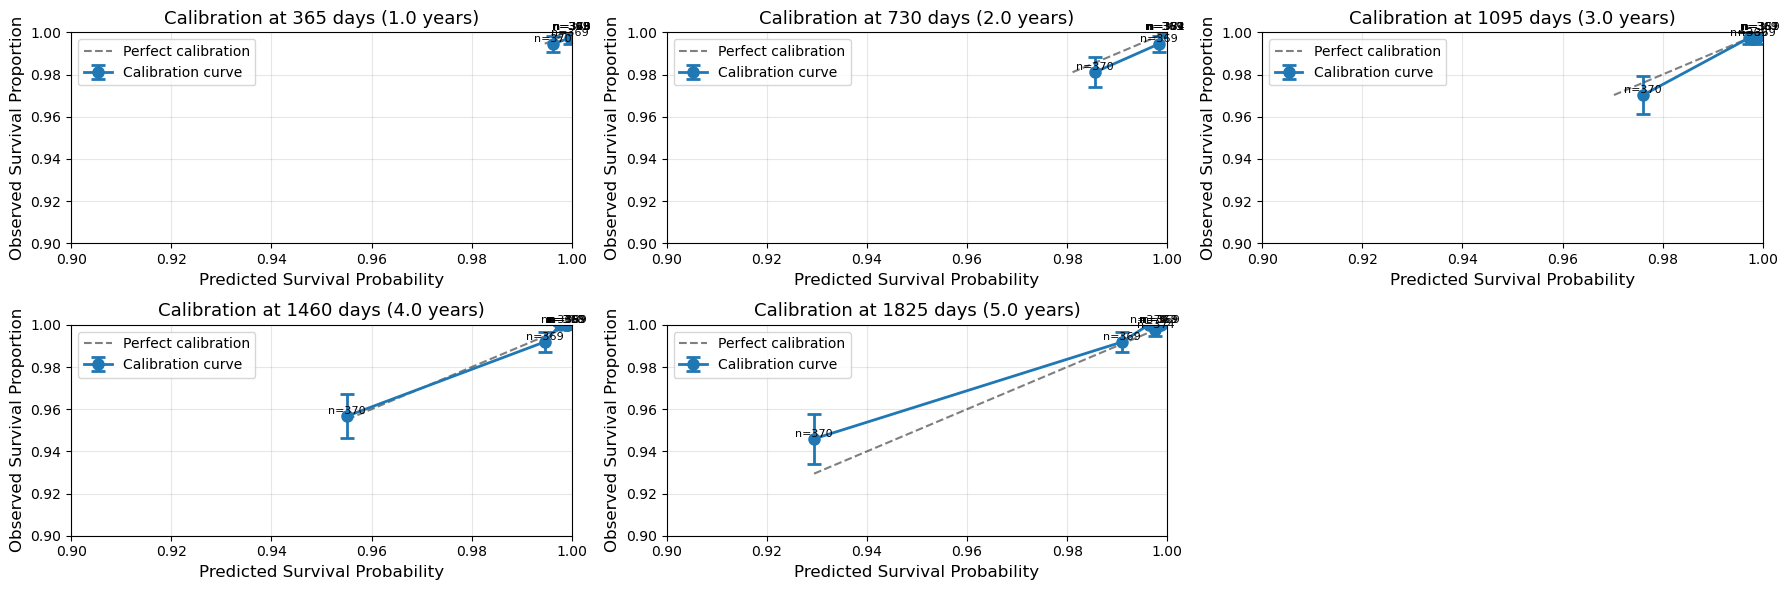

In [34]:
# Generate calibration curves for all time points
fig, axes, calibration_results = plot_calibration_curves(
    predictions_df=predictions_df,
    time_points=time_points,
    n_bins=7,
    strategy='quantile',  # Equal-sized bins based on prediction quantiles
    figsize=(18, 6),
    save_path='platt_gbm_calibration_curves.png',
    xlim=(0.9, 1),
    ylim=(0.9, 1),
    error_bar_type='se'
)

plt.show()

Jittered risk score plot saved to platt_risk_score_distribution.png

Time point 365 days:
  Events: 3, No events: 2581
  Mean survival prob (event): 0.995
  Mean survival prob (no event): 0.999
  Cohen's d: 1.22

Time point 730 days:
  Events: 9, No events: 2575
  Mean survival prob (event): 0.958
  Mean survival prob (no event): 0.998
  Cohen's d: 0.97

Time point 1095 days:
  Events: 13, No events: 2571
  Mean survival prob (event): 0.927
  Mean survival prob (no event): 0.996
  Cohen's d: 1.31

Time point 1460 days:
  Events: 19, No events: 2565
  Mean survival prob (event): 0.893
  Mean survival prob (no event): 0.993
  Cohen's d: 1.17

Time point 1825 days:
  Events: 24, No events: 2560
  Mean survival prob (event): 0.863
  Mean survival prob (no event): 0.988
  Cohen's d: 1.08


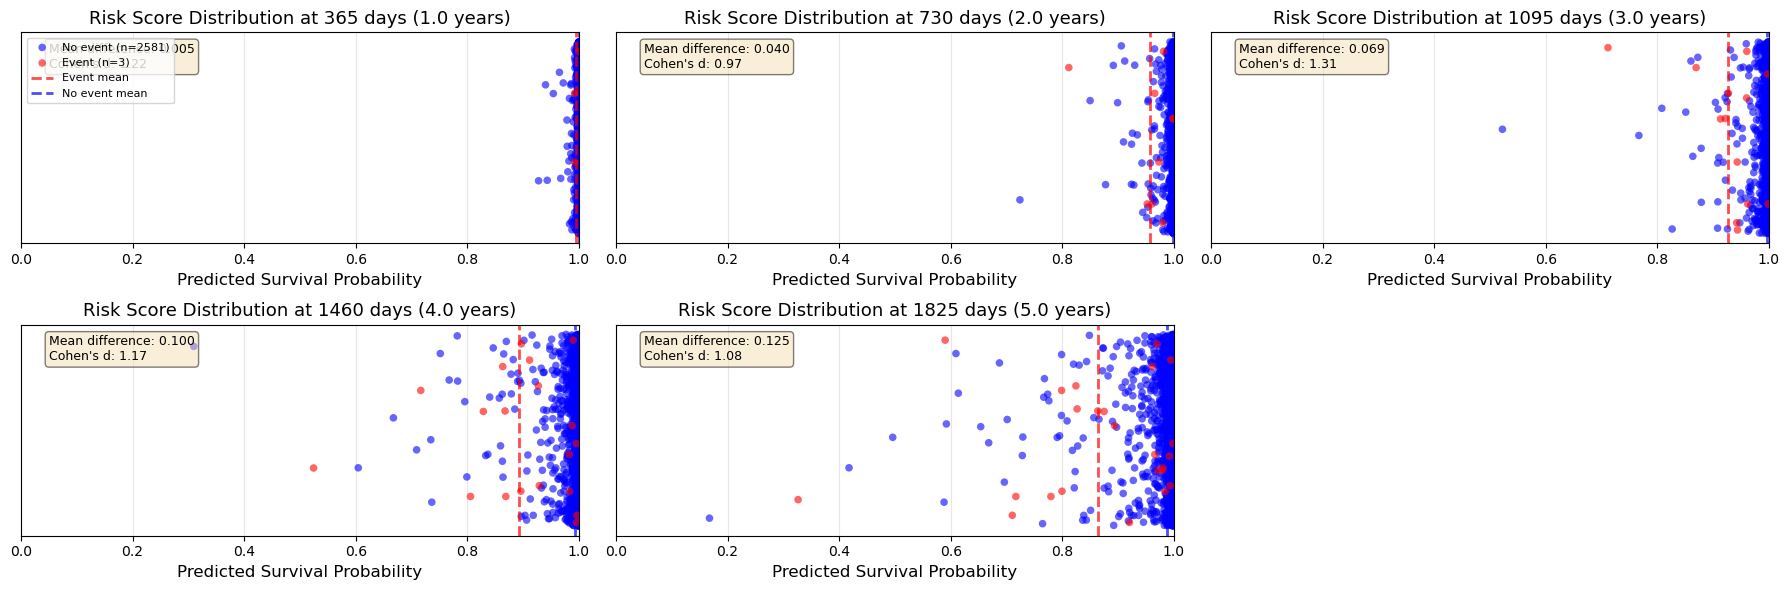

In [30]:
# Basic usage
fig, axes, stats = plot_jittered_risk_scores(
    predictions_df=predictions_df,
    time_points=time_points,
    figsize=(18, 6),
    save_path='platt_risk_score_distribution.png'
)

# Check separation statistics
for t, stat in stats.items():
    print(f"\nTime point {t} days:")
    print(f"  Events: {stat['n_events']}, No events: {stat['n_no_events']}")
    print(f"  Mean survival prob (event): {stat['event_mean']:.3f}")
    print(f"  Mean survival prob (no event): {stat['no_event_mean']:.3f}")
    print(f"  Cohen's d: {stat['cohens_d']:.2f}")

  Processing fold 1/4...
  Processing fold 2/4...
  Processing fold 3/4...
  Processing fold 4/4...

  Collected survival curves for 2584 patients


(<Figure size 1500x1000 with 1 Axes>,
 <Axes: title={'center': 'Individual Patient Survival Curves (CV Predictions)'}, xlabel='Time (days)', ylabel='Predicted Survival Probability'>,
     patient_idx  event    time event_status  n_predictions
 0           209   True   790.0        Event              1
 1           648   True  1762.0        Event              1
 2           691   True  1543.0        Event              1
 3           692   True  1543.0        Event              1
 4           696   True  1106.0        Event              1
 5           744   True  1306.0        Event              1
 6           860   True  1262.0        Event              1
 7           905   True   345.0        Event              1
 8           948   True  1351.0        Event              1
 9           975   True   278.0        Event              1
 10         1024   True   799.0        Event              1
 11         1051   True   986.0        Event              1
 12         1244   True  1695.0      

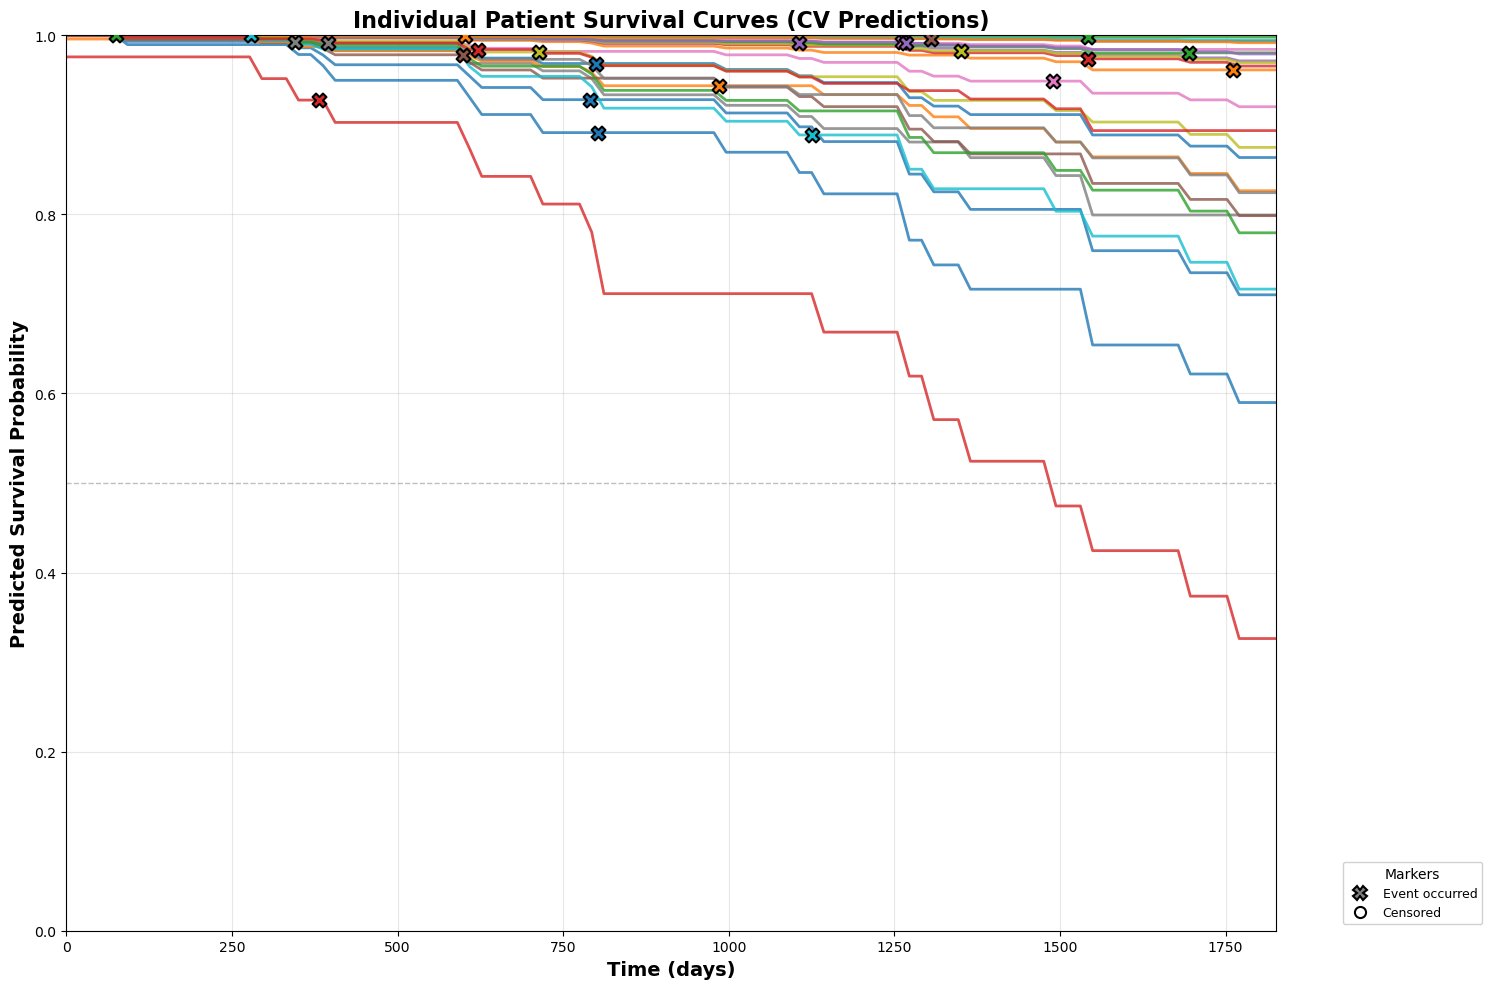

In [32]:
plot_individual_survival_curves(model_class=GradientBoostingSurvivalAnalysis, X=x_train, y=y_train, model_params=best_params_for_calibration,
                                    patient_indices=None, 
                                    n_patients=24, select_events_only=True,
                                    scale_data=False, scaler_type='standard',
                                    continuous_features=None,
                                    n_splits=4, random_state=42,
                                    time_range=None, n_time_points=100,
                                    figsize=(15, 10), save_path=None,
                                    show_event_markers=True, show_censoring_markers=True,
                                    event_marker_size=100, censoring_marker_size=80,
                                    colormap='tab10', alpha=0.8,
                                    show_legend=True, legend_outside=True,
                                    compute_weights=False, 
                                    verbose=True)

## SurvSHAP global feature importance

Just one point estimate on the **whole cohort** (3228 patients, 27 events, same 5-year
cut-off as above) — no bootstrap or CI, and scored on the whole cohort rather than the
training split.

Background sample, explained sample and timestamp grid match `cox.ipynb`, `rsf.ipynb`
and `ssvm.ipynb` exactly, so `aggregated_change` (the trapezoid integral of mean
|SurvSHAP(t)| over that grid) stays comparable across models. `shap_comparison.ipynb`
is what reads the resulting `*_survshap_global_importance.csv` files.

In [4]:
# --- Shared SurvSHAP protocol (identical text in cox/rsf/gbm/ssvm.ipynb) -----
# Everything below runs on the WHOLE cohort (data_x / data_y: 3228 patients,
# 27 events after the 5-year cut-off applied earlier in this notebook), not on
# the training split. Feature importance is a statement about the cohort, so it
# is estimated from the cohort; the train/test split above exists to report
# out-of-sample discrimination, which is a different question.
#
# Three choices are pinned here, and pinned the same way in all four notebooks,
# because `aggregated_change` is only comparable across models if they share
# them. Both data builds (`data/` and `data/data_cox/`) have identical row
# order, event and time vectors, so the seeds below select the same patients in
# every notebook even though the Cox build has 30 columns and the others 35.
#
#   BACKGROUND (N_BACKGROUND rows, plain random draw)
#       SHAP explains a prediction as a deviation from E[f(X)] over this set,
#       so it has to look like the cohort. A plain random draw keeps the real
#       ~0.84% event prevalence. Forcing every event into the background (what
#       the earlier version of these cells did) makes the reference "average
#       patient" ~25x more recurrence-prone than any real patient and shifts
#       every attribution away from the population it is meant to describe.
#
#   EXPLAINED SET (N_EXPLAINED rows: all 27 events + random non-events)
#       Here the enrichment is deliberate and is the point: global importance
#       is an average over the patients being explained, and a plain random
#       sample of 100 would contain about one event.
#
#   TIMESTAMPS (N_TIMESTAMPS points, 5th-95th percentile of ALL 27 event times)
#       `aggregated_change` is a trapezoid integral over this grid, so the grid
#       must be identical across models. It is therefore derived from data_y
#       itself, never from whichever sample happened to be drawn.
import sys, os
sys.path.insert(0, os.path.abspath('../../../survshap-main/survshap_package'))
from survshap import SurvivalModelExplainer, ModelSurvSHAP

SHAP_SEED    = 42
N_BACKGROUND = 100   # halve to 50 to roughly halve runtime, at some cost in SHAP precision
N_EXPLAINED  = 100
N_TIMESTAMPS = 20
SHAP_B       = 25    # Monte-Carlo paths for calculation_method="sampling" (survshap default)

_event_field, _time_field = data_y.dtype.names
_event = data_y[_event_field]
_time  = data_y[_time_field]
_rng   = np.random.RandomState(SHAP_SEED)

# Background: plain random draw over the whole cohort, prevalence preserved.
shap_background_idx = np.sort(_rng.choice(len(data_x), size=N_BACKGROUND, replace=False))

# Explained set: every event, topped up with random non-events.
_event_idx     = np.where(_event == 1)[0]
_non_event_idx = np.where(_event == 0)[0]
shap_explained_idx = np.sort(np.concatenate([
    _event_idx,
    _rng.choice(_non_event_idx,
                size=max(0, N_EXPLAINED - len(_event_idx)),
                replace=False),
]))

# Shared integration grid, from the full cohort's event times.
shap_timestamps = np.percentile(_time[_event == 1], np.linspace(5, 95, N_TIMESTAMPS))

print(f"cohort           : {len(data_x)} patients, {int(_event.sum())} events "
      f"({100 * _event.mean():.2f}%)")
print(f"SHAP background  : {len(shap_background_idx)} rows, "
      f"{int(_event[shap_background_idx].sum())} events (representative)")
print(f"SHAP explained   : {len(shap_explained_idx)} rows, "
      f"{int(_event[shap_explained_idx].sum())} events (all events + controls)")
print(f"SHAP timestamps  : {N_TIMESTAMPS} points, "
      f"{shap_timestamps.min():.0f}..{shap_timestamps.max():.0f} days")

cohort           : 3228 patients, 27 events (0.84%)
SHAP background  : 100 rows, 1 events (representative)
SHAP explained   : 100 rows, 27 events (all events + controls)
SHAP timestamps  : 20 points, 218..1757 days


In [5]:
# --- GBM: global SurvSHAP on the whole cohort -------------------------------
# Same estimator and settings as cox.ipynb / ssvm.ipynb: Monte-Carlo sampling
# Shapley values over SHAP_B random feature orderings, marginalised over the
# shared background set, integrated over the shared timestamp grid.
from sksurv.ensemble import GradientBoostingSurvivalAnalysis

# Final GBM refit on every patient, with the selected configuration.
# min_samples_split is deliberately left at the sksurv default (2): it was never
# a grid axis in the stage-2 search, so every CV fold that produced these
# numbers used the default.
gbm_model_full = GradientBoostingSurvivalAnalysis(
    learning_rate=0.1,
    n_estimators=2000,
    max_depth=1,
    min_samples_leaf=5,
    max_features=None,
    subsample=1.0,
    random_state=42,
)
gbm_model_full.fit(data_x, data_y)

_train_risk = gbm_model_full.predict(data_x)
print("GBM refit on the full cohort -- apparent c-index: "
      f"{concordance_index_censored(_event.astype(bool), _time, _train_risk)[0]:.4f} "
      "(in-sample, not a generalisation estimate)")

gbm_shap_explainer = SurvivalModelExplainer(
    model=gbm_model_full,
    data=data_x.iloc[shap_background_idx].reset_index(drop=True),
    y=data_y[shap_background_idx],
)

gbm_global_survshap = ModelSurvSHAP(
    calculation_method="sampling",
    aggregation_method="integral",
    B=SHAP_B,
    random_state=SHAP_SEED,
)
gbm_global_survshap.fit(
    gbm_shap_explainer,
    new_observations=data_x.iloc[shap_explained_idx].reset_index(drop=True),
    timestamps=shap_timestamps,
)

gbm_survshap_importance = (
    gbm_global_survshap.result[["variable_name", "aggregated_change"]]
    .sort_values("aggregated_change", ascending=False)
    .reset_index(drop=True)
)
gbm_survshap_importance.to_csv("gbm_survshap_global_importance.csv", index=False)
print(gbm_survshap_importance.to_string(index=False))

GBM refit on the full cohort -- apparent c-index: 0.9154 (in-sample, not a generalisation estimate)


100%|██████████| 100/100 [51:16<00:00, 30.77s/it]


                                            variable_name  aggregated_change
                          Oestrogen receptor status at CB           9.354215
         Neoadjuvant (Only) therapy with biological drugs           7.667432
                              Radiotherapy (RT) performed           2.225872
                                          Grade at CB_3.0           0.626423
                                        Isotype at CB_4.0           0.617969
                            Ki67 positive cells (%) at CB           0.465521
                     Radiotherapy on supraclavicular area           0.016192
           Diagnostic panel missingness pattern_missing_7           0.000000
Her2 overexpression (with immunohystochemistry) at CB_2.0           0.000000
Her2 overexpression (with immunohystochemistry) at CB_1.0           0.000000
                                          Grade at CB_2.0           0.000000
                                          Grade at CB_1.0           0.000000

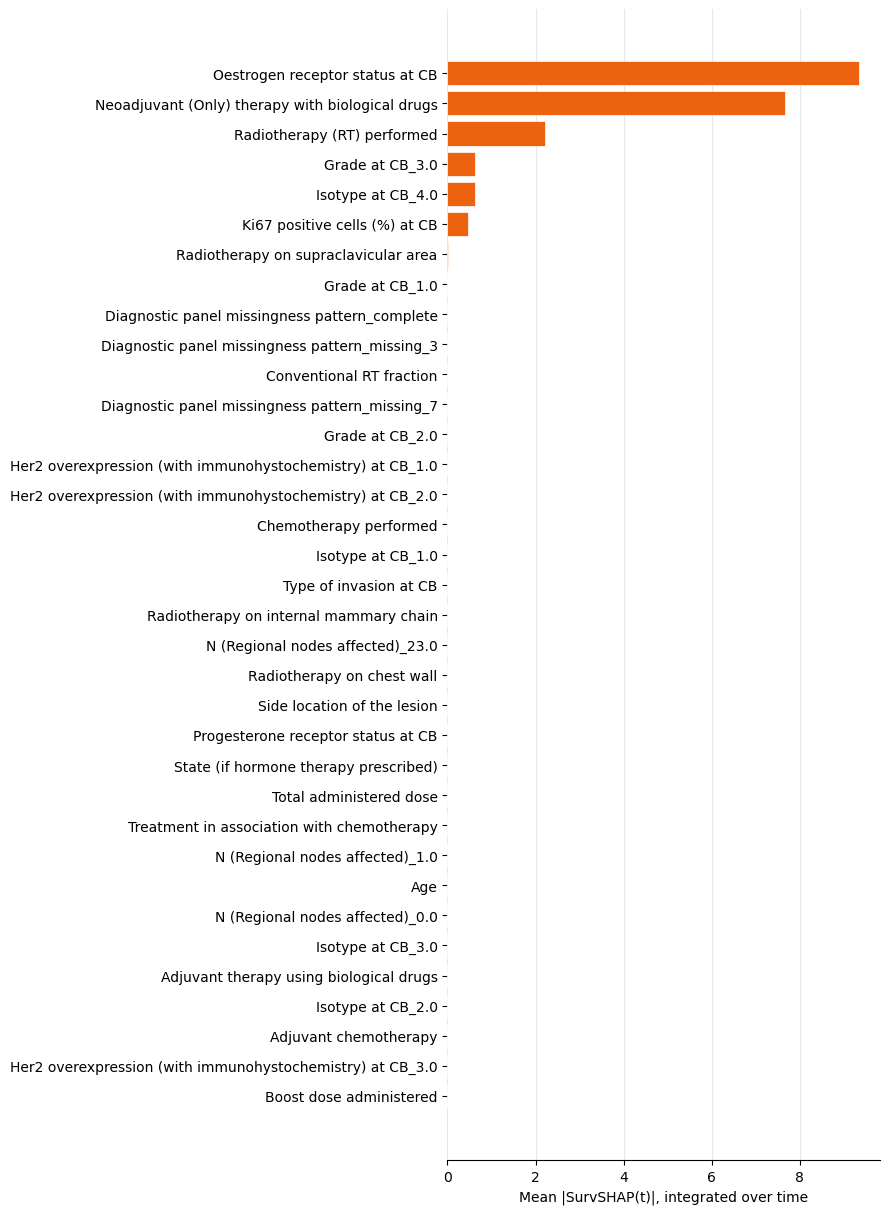

In [6]:
# --- GBM SurvSHAP global importance plot ---
# aggregated_change is a magnitude (mean |SurvSHAP(t)| integrated over the shared
# timestamp grid); it carries no sign or direction, so a single colour is used.
plot_df = gbm_survshap_importance.sort_values('aggregated_change', ascending=True).reset_index(drop=True)
y_pos = np.arange(len(plot_df))

fig, ax = plt.subplots(figsize=(9, max(4, 0.35 * len(plot_df))))
ax.set_facecolor('none')
fig.patch.set_alpha(0.0)
ax.barh(y_pos, plot_df['aggregated_change'], color=plt.cm.Oranges(0.65),
        edgecolor='white', linewidth=0.5, zorder=3)
ax.set_yticks(y_pos)
ax.set_yticklabels(plot_df['variable_name'])
ax.set_xlabel('Mean |SurvSHAP(t)|, integrated over time')
ax.grid(axis='x', color='#E2E8F0', linewidth=0.8, zorder=0)
ax.set_axisbelow(True)
for spine in ['top', 'right', 'left']:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.savefig('gbm_survshap_global_importance.png', dpi=300, transparent=True, bbox_inches='tight')
plt.savefig('gbm_survshap_global_importance.pdf', transparent=True, bbox_inches='tight')
plt.show()